# Federated Learning for IoT: Data Preparation

## Objective
Prepare data for federated learning simulation by:
1. Loading a suitable dataset
2. Partitioning data across simulated IoT devices (non-IID)
3. Visualizing data distribution across devices
4. Saving partitioned data for federated learning

## Dataset
We will use the **Human Activity Recognition (HAR) dataset** from UCI ML Repository.
- **Why this dataset?**
  - IoT-relevant (smartphone/wearable sensors)
  - Multi-class classification (6 activities)
  - Suitable for non-IID partitioning
  - Real-world sensor data

## Federated Learning Setup
- **Number of devices:** 10 simulated IoT devices
- **Data distribution:** Non-IID (each device has different activity distribution)
- **Goal:** Train a global model without sharing raw data

In [1]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
import pickle
import os
import warnings
warnings.filterwarnings('ignore')

# Set visualization style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12

# Set random seed for reproducibility
np.random.seed(42)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Option 1: Download HAR dataset from UCI
# If you have internet, run this cell

import urllib.request
import zipfile

# Create data folder if not exists
os.makedirs('../data', exist_ok=True)

# Download HAR dataset
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00240/UCI%20HAR%20Dataset.zip"
zip_path = "../data/UCI_HAR_Dataset.zip"

if not os.path.exists(zip_path):
    print("Downloading HAR dataset...")
    urllib.request.urlretrieve(url, zip_path)
    print("Download complete!")
else:
    print("Dataset already downloaded.")

# Extract
extract_path = "../data/UCI_HAR_Dataset"
if not os.path.exists(extract_path):
    print("Extracting dataset...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall("../data/")
    print("Extraction complete!")
else:
    print("Dataset already extracted.")

Download complete!
Extracting dataset...
Extraction complete!


In [4]:
# Load HAR dataset
# The dataset has:
# - X_train.txt: features (561 features)
# - y_train.txt: labels (1-6)
# - X_test.txt: test features
# - y_test.txt: test labels

# ⚠️ NOTE: Folder name has SPACES: "UCI HAR Dataset"
data_path = "../data/UCI HAR Dataset"

# Load training data
X_train = pd.read_csv(f"{data_path}/train/X_train.txt", sep=r'\s+', header=None)
y_train = pd.read_csv(f"{data_path}/train/y_train.txt", sep=r'\s+', header=None)

# Load test data
X_test = pd.read_csv(f"{data_path}/test/X_test.txt", sep=r'\s+', header=None)
y_test = pd.read_csv(f"{data_path}/test/y_test.txt", sep=r'\s+', header=None)

print("Data loaded successfully!")
print("="*60)
print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_test shape: {y_test.shape}")

print("\nClass distribution (training):")
print(y_train.value_counts().sort_index())

Data loaded successfully!
X_train shape: (7352, 561)
y_train shape: (7352, 1)
X_test shape: (2947, 561)
y_test shape: (2947, 1)

Class distribution (training):
0
1    1226
2    1073
3     986
4    1286
5    1374
6    1407
Name: count, dtype: int64


In [5]:
# Convert to numpy arrays
X_train = X_train.values
y_train = y_train.values.ravel()
X_test = X_test.values
y_test = y_test.values.ravel()

# Map labels to activity names
activity_names = {
    1: 'Walking',
    2: 'Walking Upstairs',
    3: 'Walking Downstairs',
    4: 'Sitting',
    5: 'Standing',
    6: 'Laying'
}

# Show class distribution
print("Activity Distribution (Training Set):")
print("="*60)
for label, name in activity_names.items():
    count = np.sum(y_train == label)
    percentage = count / len(y_train) * 100
    print(f"{name}: {count:,} samples ({percentage:.2f}%)")

Activity Distribution (Training Set):
Walking: 1,226 samples (16.68%)
Walking Upstairs: 1,073 samples (14.59%)
Walking Downstairs: 986 samples (13.41%)
Sitting: 1,286 samples (17.49%)
Standing: 1,374 samples (18.69%)
Laying: 1,407 samples (19.14%)


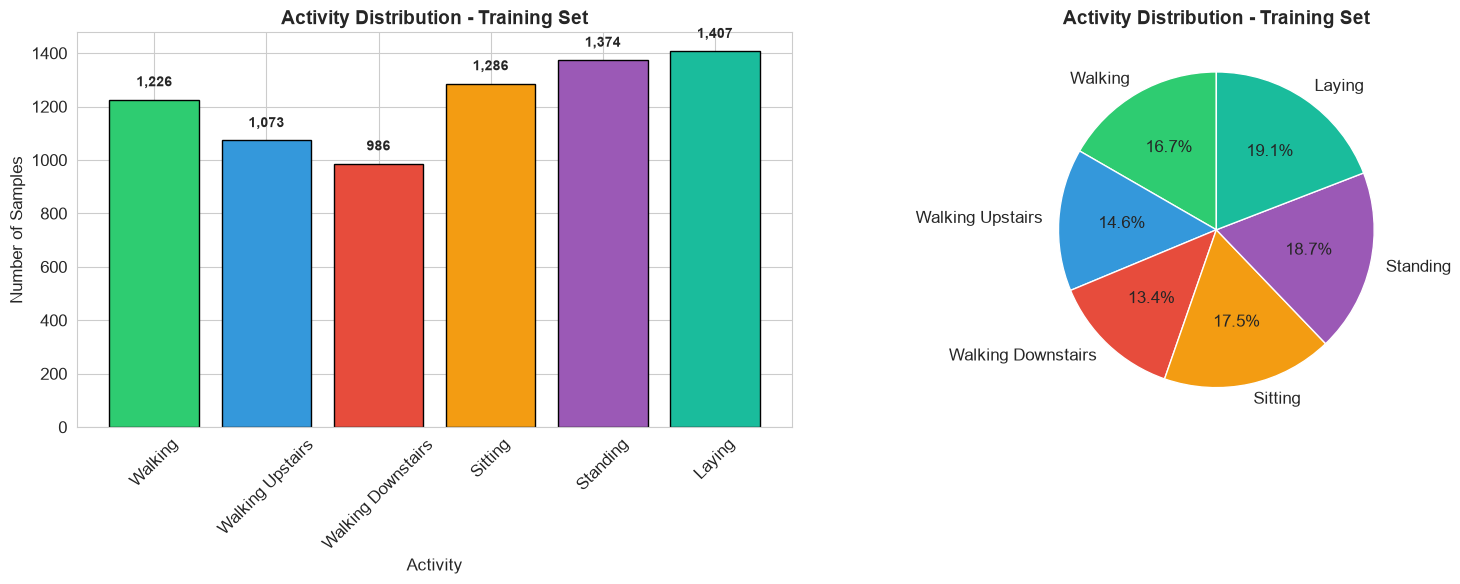

Figure saved to results/figures/activity_distribution.png


In [6]:
# Visualize class distribution
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Bar chart
labels = [activity_names[i] for i in range(1, 7)]
counts = [np.sum(y_train == i) for i in range(1, 7)]
colors = ['#2ecc71', '#3498db', '#e74c3c', '#f39c12', '#9b59b6', '#1abc9c']

bars = axes[0].bar(labels, counts, color=colors, edgecolor='black')
axes[0].set_title('Activity Distribution - Training Set', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Activity')
axes[0].set_ylabel('Number of Samples')
axes[0].tick_params(axis='x', rotation=45)

for bar, count in zip(bars, counts):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
                 f'{count:,}', ha='center', fontsize=10, fontweight='bold')

# Pie chart
axes[1].pie(counts, labels=labels, autopct='%1.1f%%', colors=colors, startangle=90)
axes[1].set_title('Activity Distribution - Training Set', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig('../results/figures/activity_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

print("Figure saved to results/figures/activity_distribution.png")

In [7]:
# Normalize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Features normalized using StandardScaler.")
print(f"Training data - Mean: {X_train_scaled.mean():.4f}, Std: {X_train_scaled.std():.4f}")

Features normalized using StandardScaler.
Training data - Mean: 0.0000, Std: 1.0000


In [8]:
# Federated Learning Setup: Partition data across devices (non-IID)
# We'll simulate 10 IoT devices, each with different activity distributions

NUM_DEVICES = 10

def partition_data_non_iid(X, y, num_devices, alpha=0.5):
    """
    Partition data across devices using Dirichlet distribution for non-IID.
    
    Args:
        X: Features
        y: Labels
        num_devices: Number of devices
        alpha: Dirichlet concentration parameter (lower = more non-IID)
    
    Returns:
        List of (X_device, y_device) tuples
    """
    num_classes = len(np.unique(y))
    device_data = [[] for _ in range(num_devices)]
    device_labels = [[] for _ in range(num_devices)]
    
    for class_idx in range(1, num_classes + 1):
        # Get indices for this class
        class_indices = np.where(y == class_idx)[0]
        np.random.shuffle(class_indices)
        
        # Dirichlet distribution for non-IID partitioning
        proportions = np.random.dirichlet([alpha] * num_devices)
        
        # Split indices according to proportions
        split_points = (np.cumsum(proportions) * len(class_indices)).astype(int)[:-1]
        class_splits = np.split(class_indices, split_points)
        
        # Assign to devices
        for device_idx, split in enumerate(class_splits):
            device_data[device_idx].extend(split)
    
    # Shuffle within each device and create arrays
    devices = []
    for device_idx in range(num_devices):
        indices = np.array(device_data[device_idx])
        np.random.shuffle(indices)
        devices.append((X[indices], y[indices]))
    
    return devices

# Partition data
devices = partition_data_non_iid(X_train_scaled, y_train, NUM_DEVICES, alpha=0.5)

print(f"Data partitioned across {NUM_DEVICES} devices (non-IID).")
print("="*60)
for i, (X_dev, y_dev) in enumerate(devices):
    print(f"Device {i+1}: {len(X_dev):,} samples")

Data partitioned across 10 devices (non-IID).
Device 1: 673 samples
Device 2: 856 samples
Device 3: 1,064 samples
Device 4: 1,125 samples
Device 5: 693 samples
Device 6: 503 samples
Device 7: 615 samples
Device 8: 330 samples
Device 9: 928 samples
Device 10: 565 samples


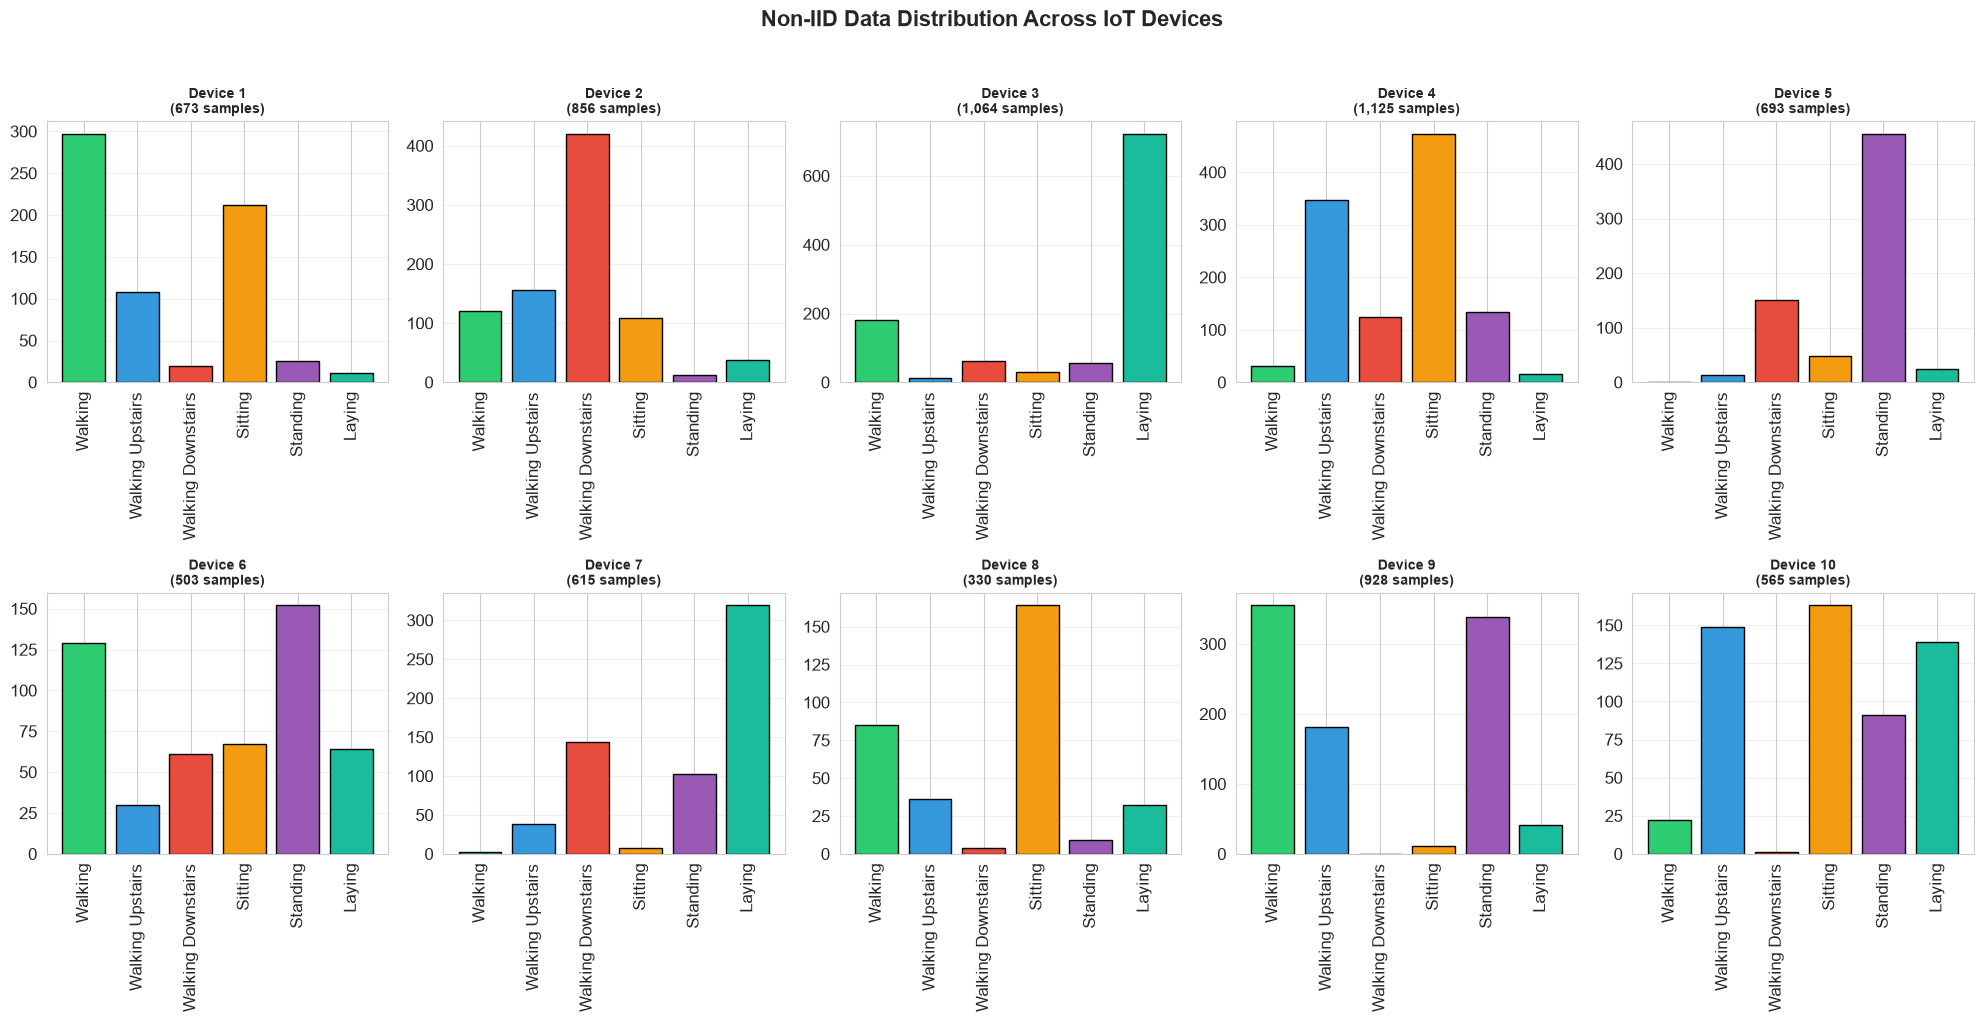

Figure saved to results/figures/non_iid_distribution.png


In [9]:
# Visualize data distribution across devices
fig, axes = plt.subplots(2, 5, figsize=(20, 10))
axes = axes.flatten()

for device_idx in range(NUM_DEVICES):
    X_dev, y_dev = devices[device_idx]
    
    # Count activities per device
    counts = [np.sum(y_dev == i) for i in range(1, 7)]
    
    axes[device_idx].bar(labels, counts, color=colors, edgecolor='black')
    axes[device_idx].set_title(f'Device {device_idx+1}\n({len(X_dev):,} samples)', 
                               fontsize=10, fontweight='bold')
    axes[device_idx].tick_params(axis='x', rotation=90)
    axes[device_idx].grid(True, alpha=0.3, axis='y')

plt.suptitle('Non-IID Data Distribution Across IoT Devices', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../results/figures/non_iid_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

print("Figure saved to results/figures/non_iid_distribution.png")

In [10]:
# Save partitioned data for federated learning
federated_data = {
    'devices': devices,
    'X_test': X_test_scaled,
    'y_test': y_test,
    'activity_names': activity_names,
    'num_devices': NUM_DEVICES
}

with open('../data/federated_data.pkl', 'wb') as f:
    pickle.dump(federated_data, f)

print("Federated data saved to data/federated_data.pkl")
print("\nReady for Federated Learning (Notebook 2)")

Federated data saved to data/federated_data.pkl

Ready for Federated Learning (Notebook 2)


In [11]:
import pickle
import os

print("Checking Notebook 1 outputs:")
print("="*60)

files = [
    '../data/federated_data.pkl',
    '../results/figures/activity_distribution.png',
    '../results/figures/non_iid_distribution.png'
]

for f in files:
    exists = os.path.exists(f)
    size = f"{os.path.getsize(f)/1024:.1f} KB" if exists else "N/A"
    print(f"{'✅' if exists else '❌'} {f} ({size})")

# Load and verify federated data
with open('../data/federated_data.pkl', 'rb') as f:
    data = pickle.load(f)

print("\nFederated data summary:")
print("="*60)
print(f"Number of devices: {data['num_devices']}")
print(f"Test samples: {len(data['y_test'])}")
print(f"Activity classes: {list(data['activity_names'].values())}")

print("\nDevice sizes:")
for i, (X_dev, y_dev) in enumerate(data['devices']):
    print(f"  Device {i+1}: {len(X_dev):,} samples")

Checking Notebook 1 outputs:
✅ ../data/federated_data.pkl (45220.2 KB)
✅ ../results/figures/activity_distribution.png (283.1 KB)
✅ ../results/figures/non_iid_distribution.png (620.9 KB)

Federated data summary:
Number of devices: 10
Test samples: 2947
Activity classes: ['Walking', 'Walking Upstairs', 'Walking Downstairs', 'Sitting', 'Standing', 'Laying']

Device sizes:
  Device 1: 673 samples
  Device 2: 856 samples
  Device 3: 1,064 samples
  Device 4: 1,125 samples
  Device 5: 693 samples
  Device 6: 503 samples
  Device 7: 615 samples
  Device 8: 330 samples
  Device 9: 928 samples
  Device 10: 565 samples


## Summary

### What We Did
1. ✅ Loaded Human Activity Recognition (HAR) dataset
2. ✅ Normalized features using StandardScaler
3. ✅ Partitioned data across 10 simulated IoT devices (non-IID)
4. ✅ Visualized data distribution across devices
5. ✅ Saved partitioned data for federated learning

### Dataset Summary
| Property | Value |
|----------|-------|
| **Source** | UCI HAR Dataset |
| **Features** | 561 |
| **Classes** | 6 activities |
| **Training samples** | ~7,352 |
| **Test samples** | ~2,947 |

### Federated Learning Setup
| Property | Value |
|----------|-------|
| **Number of devices** | 10 |
| **Data distribution** | Non-IID (each device has different activity mix) |
| **Goal** | Train global model without sharing raw data |

### What's Next
In Notebook 2 (`02_federated_learning.ipynb`), we will:
1. Define a neural network model
2. Implement FedAvg from scratch
3. Train across devices (multiple rounds)
4. Compare with centralized learning

### Saved Files
- `federated_data.pkl`: Partitioned data for FL
- `activity_distribution.png`: Overall class distribution
- `non_iid_distribution.png`: Per-device distribution